Archivos: 166 de 166
Meses que faltan: []
Filas totales: (43422, 3)
anio
2013    62.2
2014    64.3
2015    66.5
2016    65.9
2017    66.7
2018    68.9
2019    70.1
2020    69.3
2021    73.9
2022    76.9
2023    80.7
2024    83.3
2025    84.4
2026    74.0
Name: GWh, dtype: float64


Text(0, 0.5, 'GWh')

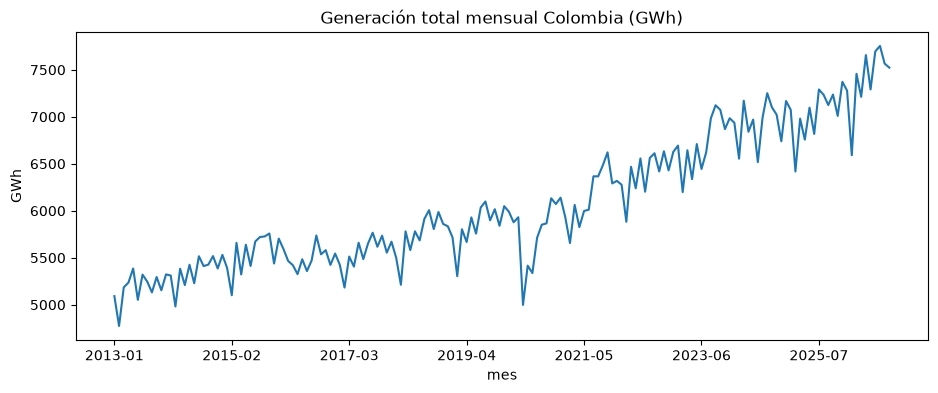

In [1]:
from pathlib import Path
import pandas as pd

carpeta = Path("../data/raw/generacion_mensual")
archivos = sorted(carpeta.glob("*.csv"))

# 1. ¿Están todos los meses?
esperados = pd.period_range("2013-01", "2026-10", freq="M").astype(str)
presentes = [a.stem for a in archivos]
faltan = sorted(set(esperados) - set(presentes))
print(f"Archivos: {len(archivos)} de {len(esperados)}")
print("Meses que faltan:", faltan)

# 2. Unir todo en una sola tabla
gen = pd.concat((pd.read_csv(a) for a in archivos), ignore_index=True)
print("Filas totales:", gen.shape)

# 3. Totales anuales en TWh (2026 solo llega a octubre)
gen["anio"] = gen["mes"].str[:4]
anual = gen.groupby("anio")["GWh"].sum() / 1000
print(anual.round(1))

# 4. Serie mensual para detectar meses raros
total_mes = gen.groupby("mes")["GWh"].sum()
ax = total_mes.plot(figsize=(11, 4), title="Generación total mensual Colombia (GWh)")
ax.set_ylabel("GWh")

In [2]:
gen.drop(columns="anio").to_csv("../data/processed/generacion_mensual_planta.csv", index=False)

In [3]:
from pydataxm.pydatasimem import ReadSIMEM

# 1. Foto del listado el día 1 de cada mes (tarda unos minutos)
fechas = pd.date_range("2013-01-01", "2026-10-01", freq="MS")
listados = []
for f in fechas:
    d = f.strftime("%Y-%m-%d")
    try:
        u = ReadSIMEM("670221", d, d).main()
        listados.append(u[["CodigoPlanta", "TipoGeneracion"]])
    except Exception as e:
        print(d, "error:", e)

tipos = pd.concat(listados).drop_duplicates()

# 2. ¿Alguna planta con más de un tipo?
dobles = tipos[tipos["CodigoPlanta"].duplicated(keep=False)]
print("Plantas con más de un tipo:", dobles["CodigoPlanta"].nunique())
print(dobles.sort_values("CodigoPlanta"))
print(tipos["TipoGeneracion"].value_counts())

****************************************************************************************************
Initializing object
The object has been initialized with the dataset: "Listado de unidades de generación"
****************************************************************************************************
Inicio consulta sincronica
Creacion url: 0.00039005279541015625
Extraccion de registros: 4.823460102081299
End of data extracting process
****************************************************************************************************
****************************************************************************************************
Initializing object
The object has been initialized with the dataset: "Listado de unidades de generación"
****************************************************************************************************
Inicio consulta sincronica
Creacion url: 0.00020766258239746094
Extraccion de registros: 3.821357250213623
End of data extracting process
*******

In [4]:
# 1. ¿Cuántas fotos llegaron, de 166?
print("Fotos guardadas:", len(listados))

# 2. ¿Cuántas filas trae cada foto?
tamanos = pd.Series([len(l) for l in listados])
print(tamanos.describe())
print("Fotos vacías:", (tamanos == 0).sum())

# 3. ¿Qué trae la última foto (la más reciente)?
print(listados[-1]["TipoGeneracion"].value_counts())

Fotos guardadas: 166
count    166.000000
mean     331.698795
std      149.208395
min      184.000000
25%      227.000000
50%      271.000000
75%      431.000000
max      788.000000
dtype: float64
Fotos vacías: 0
TipoGeneracion
Solar         371
Hidraulica    284
Termica       130
Eolica          3
Name: count, dtype: int64


In [5]:
print("Plantas únicas:", tipos["CodigoPlanta"].nunique())
print("Pares planta-tipo:", len(tipos))
print(tipos["TipoGeneracion"].value_counts())

dobles = tipos[tipos["CodigoPlanta"].duplicated(keep=False)]
print("Plantas con más de un tipo:", dobles["CodigoPlanta"].nunique())
print(dobles.sort_values("CodigoPlanta").head(20))

Plantas únicas: 659
Pares planta-tipo: 661
TipoGeneracion
Solar         376
Hidraulica    169
Termica       112
Eolica          4
Name: count, dtype: int64
Plantas con más de un tipo: 2
    CodigoPlanta TipoGeneracion
1           2TYI          Solar
244         2TYI        Termica
232         2VJS        Termica
1           2VJS          Solar


In [6]:
# Unir las fotos guardando su orden en el tiempo
todas = pd.concat([l.assign(foto=i) for i, l in enumerate(listados)])

# ¿En qué fotos aparece cada tipo para las 2 plantas dudosas?
dudosas = ["2TYI", "2VJS"]
print(todas[todas["CodigoPlanta"].isin(dudosas)]
      .groupby(["CodigoPlanta", "TipoGeneracion"])["foto"].agg(["min", "max", "count"]))

# ¿Cuánta energía generaron en total?
print(gen[gen["CodigoPlanta"].isin(dudosas)].groupby("CodigoPlanta")["GWh"].sum())

                             min  max  count
CodigoPlanta TipoGeneracion                 
2TYI         Solar            60  165    106
             Termica          68   82     15
2VJS         Solar            83  165     83
             Termica          74   82      9
CodigoPlanta
2TYI     49.143641
2VJS    110.655369
Name: GWh, dtype: float64


Filas antes/después: 43422 43422
count    166.00
mean       0.07
std        0.16
min        0.00
25%        0.00
50%        0.01
75%        0.08
max        1.68
Name: GWh, dtype: float64


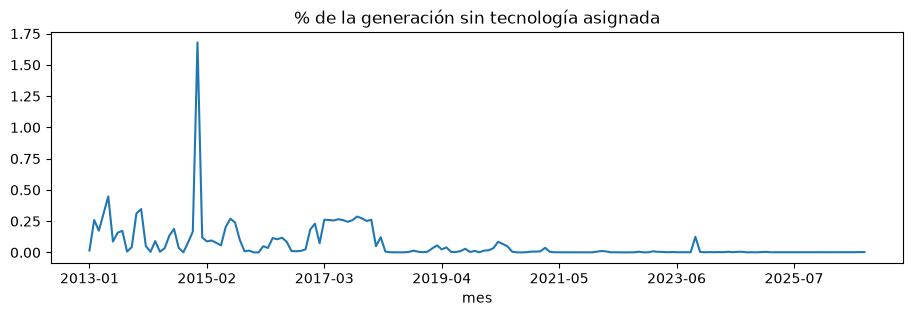

In [7]:
# 1. Una fila por planta: la clasificación más reciente
tipos = (
    todas.sort_values("foto")
         .drop_duplicates(subset="CodigoPlanta", keep="last")
         [["CodigoPlanta", "TipoGeneracion"]]
)

# 2. Unir con la generación y comprobar que no se duplicaron filas
gen_t = gen.merge(tipos, on="CodigoPlanta", how="left")
print("Filas antes/después:", len(gen), len(gen_t))   # deben ser iguales
gen_t["TipoGeneracion"] = gen_t["TipoGeneracion"].fillna("Sin clasificar")

# 3. Control de calidad: % de generación sin clasificar por mes
total_mes = gen_t.groupby("mes")["GWh"].sum()
sin_mes = gen_t[gen_t["TipoGeneracion"] == "Sin clasificar"].groupby("mes")["GWh"].sum()
pct_sin = (sin_mes.reindex(total_mes.index, fill_value=0) / total_mes * 100)
print(pct_sin.describe().round(2))
pct_sin.plot(figsize=(11, 3), title="% de la generación sin tecnología asignada")

# 4. Guardar
gen_t.to_csv("../data/processed/generacion_mensual_tecnologia.csv", index=False)